# 01 · Preprocessing and dataset

**Task.** Classify every squat repetition into one of 6 classes (`correct`, `insufficient_depth`, `forward_lean`,
`knee_valgus`, `knee_varus`, `heel_lift`) from the 3D skeleton of the two-camera (front + side) Pose2Sim pipeline.

This notebook builds the dataset, **checks that the preprocessing is correct**, and visualises the data.
No model is trained here.

**How to run.** Kernel *Python (SquatModelVenv)*, Run All (about 1 minute).
**Outputs.** `results/01_dataset/` (tables and figures).

In [1]:
# ---- setup (every notebook starts with this cell) ----
import sys, json, time, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()     # research_folders/
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display, Markdown, clear_output, Image
pd.set_option("display.precision", 3); pd.set_option("display.width", 160); pd.set_option("display.max_colwidth", 120)
from squat_research.common import load_config, apply_overrides, results_dir, nice, read_json, write_json
from squat_research.dataset import build_dataset, load_dataset
from squat_research.engine import comparison_table, select_best, fold_scores, paired_test
from squat_research import viz, monitor
cfg = load_config()
print("research folder:", ROOT)
OUT = results_dir(cfg, "01_dataset")

research folder: C:\Users\dynam\Desktop\Project1\research_folders


## 1. Which recordings are used

| rule | why |
|---|---|
| class `abnormal_tempo` left out | people did not follow the speed protocol; the error is a rhythm across reps, not visible in one rep |
| person `E_PANTS_MALE` left out of training | loose trousers: neck, shoulders and legs poorly triangulated (used as an unseen-person check in notebook 04) |
| `p01` left out | early test export of p1, not in KEY_INFO |
| KEY_INFO file errors (p4, p50, p70, p71, p76, p105) | no output or only 0-2 reps recorded |
| rep filters | lower-body joint missing > 25 % of a rep; Neck missing > 50 % (the pipeline's trunk angles are wrong without it); duration outside 0.5-10 s after trimming |

In [2]:
man, npz = build_dataset(cfg)
display(man[~man["include"]][["id", "person", "label", "reason"]].reset_index(drop=True))
print(f"{man['include'].sum()} of {len(man)} recordings included")
ds = load_dataset(cfg); C = ds["classes"]
summary = pd.DataFrame({"recordings": [len(set(ds["recording"][ds["y"] == i])) for i in range(len(C))],
                        "reps": np.bincount(ds["y"], minlength=len(C)),
                        "persons": [len(set(ds["person"][ds["y"] == i])) for i in range(len(C))]}, index=C)
summary.loc["total"] = [len(set(ds["recording"])), len(ds["y"]), len(set(ds["person"]))]
summary.to_csv(OUT / "dataset_summary.csv")
print(f"{len(ds['y'])} reps used, {ds['n_filtered']} reps removed by the quality filters"); display(summary)

103 recordings -> 1068 reps in 11 s -> C:\Users\dynam\Desktop\Project1\research_folders\data\processed\reps_T64.npz


,id,person,label,reason
0,p01,NaN,correct,"excluded id (test export, not in KEY_INFO)"
1,p4,A,knee_valgus,KEY_INFO: NO CSV REPORTS
2,p13,B,abnormal_tempo,class abnormal_tempo not studied
3,p20,C,abnormal_tempo,class abnormal_tempo not studied
4,p22,E_PANTS_MALE,correct,excluded person E_PANTS_MALE
5,p24,E_PANTS_MALE,insufficient_depth,excluded person E_PANTS_MALE
6,p26,E_PANTS_MALE,forward_lean,excluded person E_PANTS_MALE
7,p28,E_PANTS_MALE,knee_valgus,excluded person E_PANTS_MALE
8,p30,E_PANTS_MALE,knee_varus,excluded person E_PANTS_MALE
9,p32,E_PANTS_MALE,heel_lift,excluded person E_PANTS_MALE


103 of 133 recordings included
933 reps used, 135 reps removed by the quality filters


,recordings,reps,persons
correct,13,134,13
insufficient_depth,13,133,13
forward_lean,17,170,17
knee_valgus,14,144,14
knee_varus,16,163,16
heel_lift,18,189,18
total,91,933,18


## 2. Preprocessing (per recording, `squat_research/features.py`)

| step | what | why |
|---|---|---|
| 1. load | `points3d.trc`: 22 joints, metres, 29.97 fps. Joints written as exactly (0,0,0) are **missing** and interpolated in time; `Hip` is rebuilt from the two hip joints | Pose2Sim writes untriangulated joints as (0,0,0) |
| 2. body frame | *up* = real standing direction ankles → hips (frames where the hips are highest); *forward* = heel → toe of both feet; *lateral* = up × forward; left / right labels checked | the camera-world axes depend on how the calibration board was held; the Neck is missing for whole recordings of some people, so it is not used |
| 3. normalise | hip-centred, divided by the leg length (hip-knee + knee-ankle) | removes body size and position |
| 4. cut + trim | reps from `reps.csv`, trimmed to the movement: start / end where knee flexion is within 10 % of its range above the standing level, **taken separately before and after the bottom** | people rest between reps with slightly bent knees; that rest must not be part of the rep |
| 5. resample | each rep to T = 64 frames (linear) | equal length for every model |
| 6. inputs | joint tokens 64 × 22 × 6 (position + velocity), frame features 64 × 19 (14 pipeline angles + knee offset L/R, heel height L/R, hip height), tempo 4 (duration, descent, ascent, bottom fraction), summary row 46 (classical baselines) | resampling hides speed, so tempo is kept separately |

## 3. Is the preprocessing correct? (checks on every rep)

In [3]:
from squat_research.checks import run_checks
chk = run_checks(ds); chk.to_csv(OUT / "preprocessing_checks.csv", index=False)
print(f"{(chk['result'] == 'PASS').sum()} of {len(chk)} checks pass")
display(chk)

19 of 19 checks pass


,group,check,result,value,expected
0,values,"no NaN / inf in joints, frame features, tempo",PASS,-,all finite
1,values,joint positions within 2.5 leg lengths of the hip,PASS,max 2.48,<= 2.5
2,values,joint speed (99th percentile of the per-rep maximum),PASS,11.8 leg lengths/s,< 15
3,body frame,knees below the hip at the rep start,PASS,99.0 % of reps,>= 99 %
4,body frame,ankles below the knees,PASS,100.0 % of reps,>= 99 %
5,body frame,toes in front of the heels (forward axis),PASS,100.0 % of reps,>= 99 %
6,body frame,left hip on the left side (lateral axis),PASS,100.0 % of reps,>= 99 %
7,body frame,leg length per recording,PASS,0.73-0.98 m,0.60-1.05 m
8,trimming,rep starts moving (knee flexion rises within the first 15 %),PASS,0.1 % flat,< 3 %
9,trimming,rep ends moving (knee flexion falls within the last 15 %),PASS,0.2 % flat,< 3 %


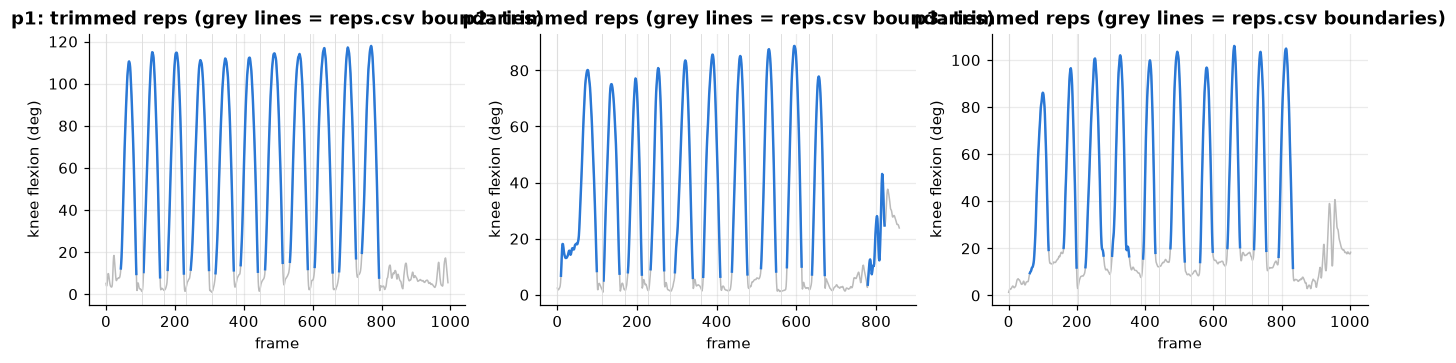

In [4]:
# trimming examples: knee flexion of the whole recording (grey) and the trimmed reps used by the models (blue)
from squat_research.features import load_recording, trim_rep, ANGLE_COLS
from squat_research.common import path
rec_ids = list(dict.fromkeys(ds["recording"]))[:3]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
for ax, rid in zip(axes, rec_ids):
    rec = load_recording(path(cfg, "recordings") / rid)
    a = rec["angles"]; flex = np.nanmean(a[:, [ANGLE_COLS.index("knee_flexion_L"), ANGLE_COLS.index("knee_flexion_R")]], axis=1)
    ax.plot(flex, color="#bbb", lw=1)
    for _, r in rec["reps"].iterrows():
        s, e, b = trim_rep(flex, int(r["start_frame"]), min(int(r["end_frame"]), len(flex) - 1))
        ax.plot(range(s, e + 1), flex[s:e + 1], color=viz.ATTN, lw=1.6); ax.axvline(r["start_frame"], color="#ddd", lw=0.6)
    ax.set(title=f"{rid}: trimmed reps (grey lines = reps.csv boundaries)", xlabel="frame", ylabel="knee flexion (deg)")
viz.save(fig, OUT, "trimming_examples"); plt.show()

## 4. The dataset

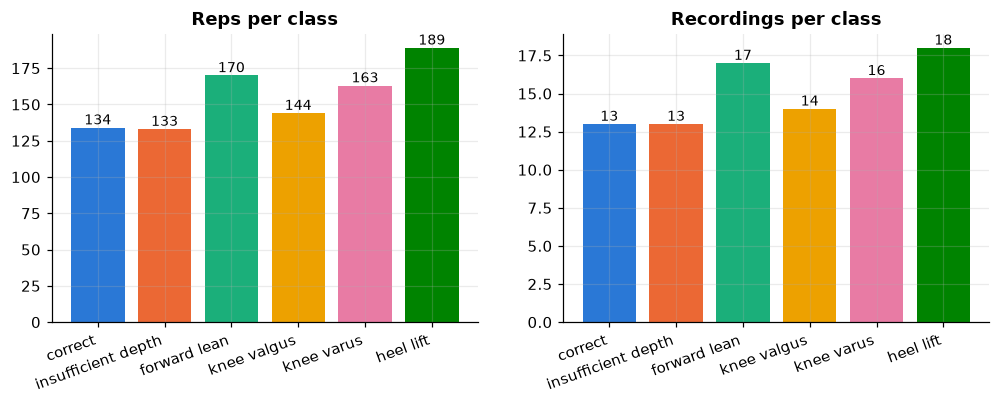

In [5]:
viz.class_counts(ds, OUT); plt.show()

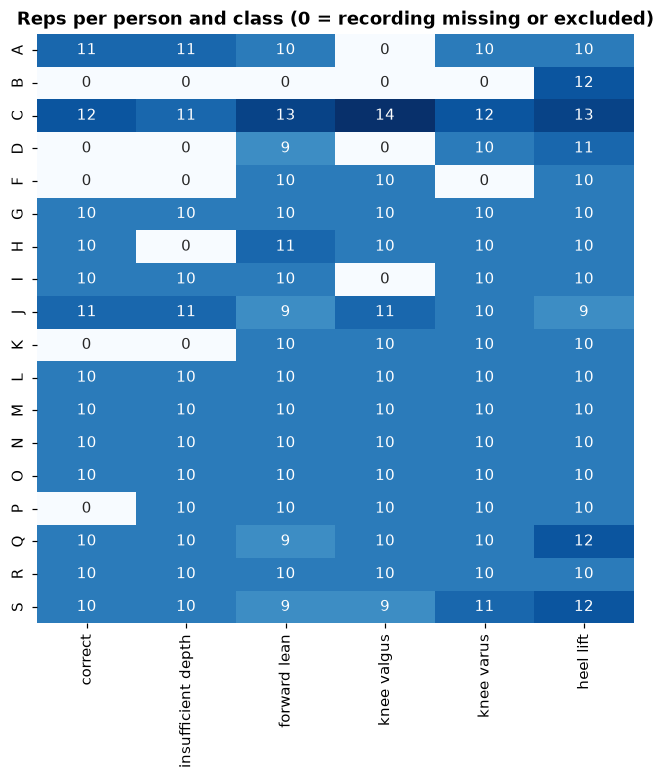

In [6]:
viz.person_class_matrix(ds, OUT); plt.show()

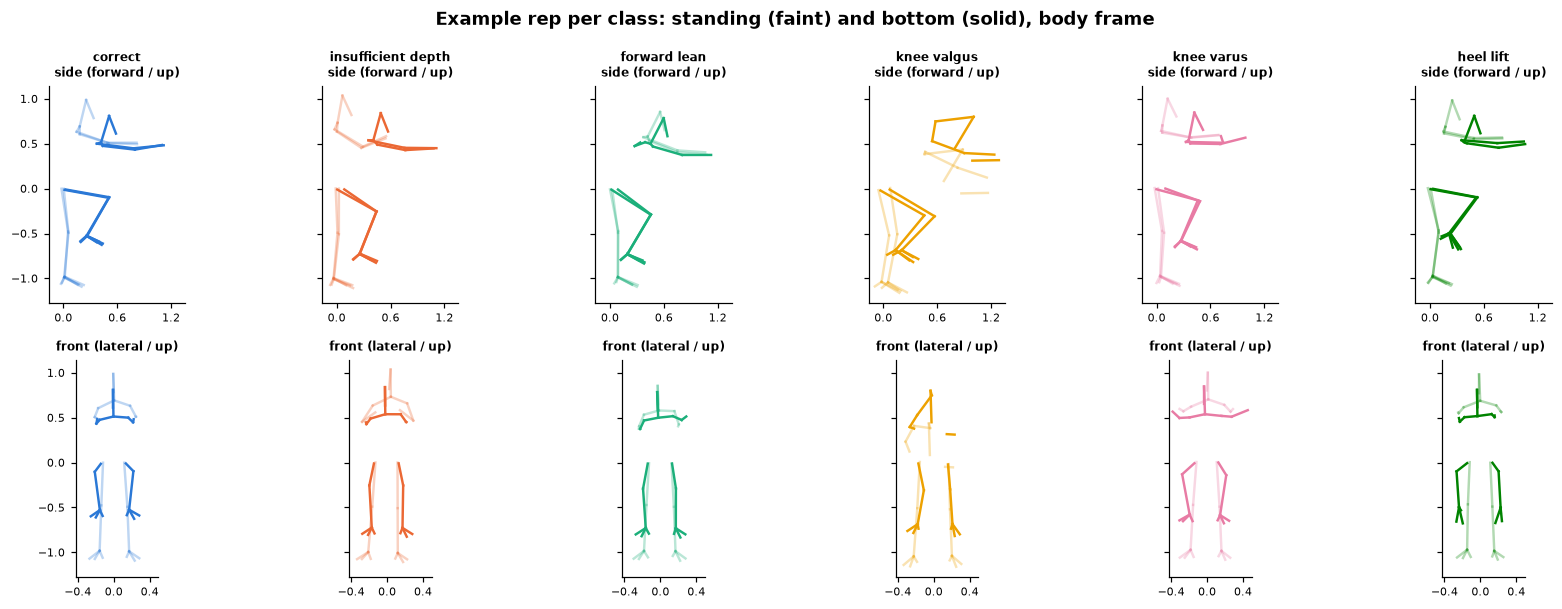

In [7]:
viz.skeleton_example(ds, OUT); plt.show()

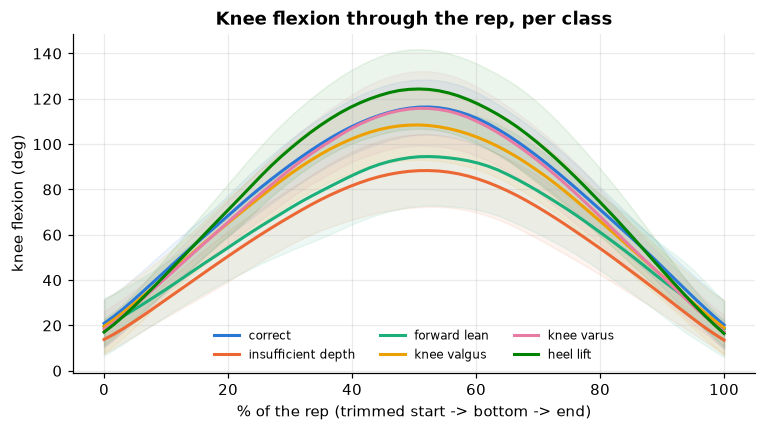

In [8]:
viz.flex_curves(ds, OUT); plt.show()

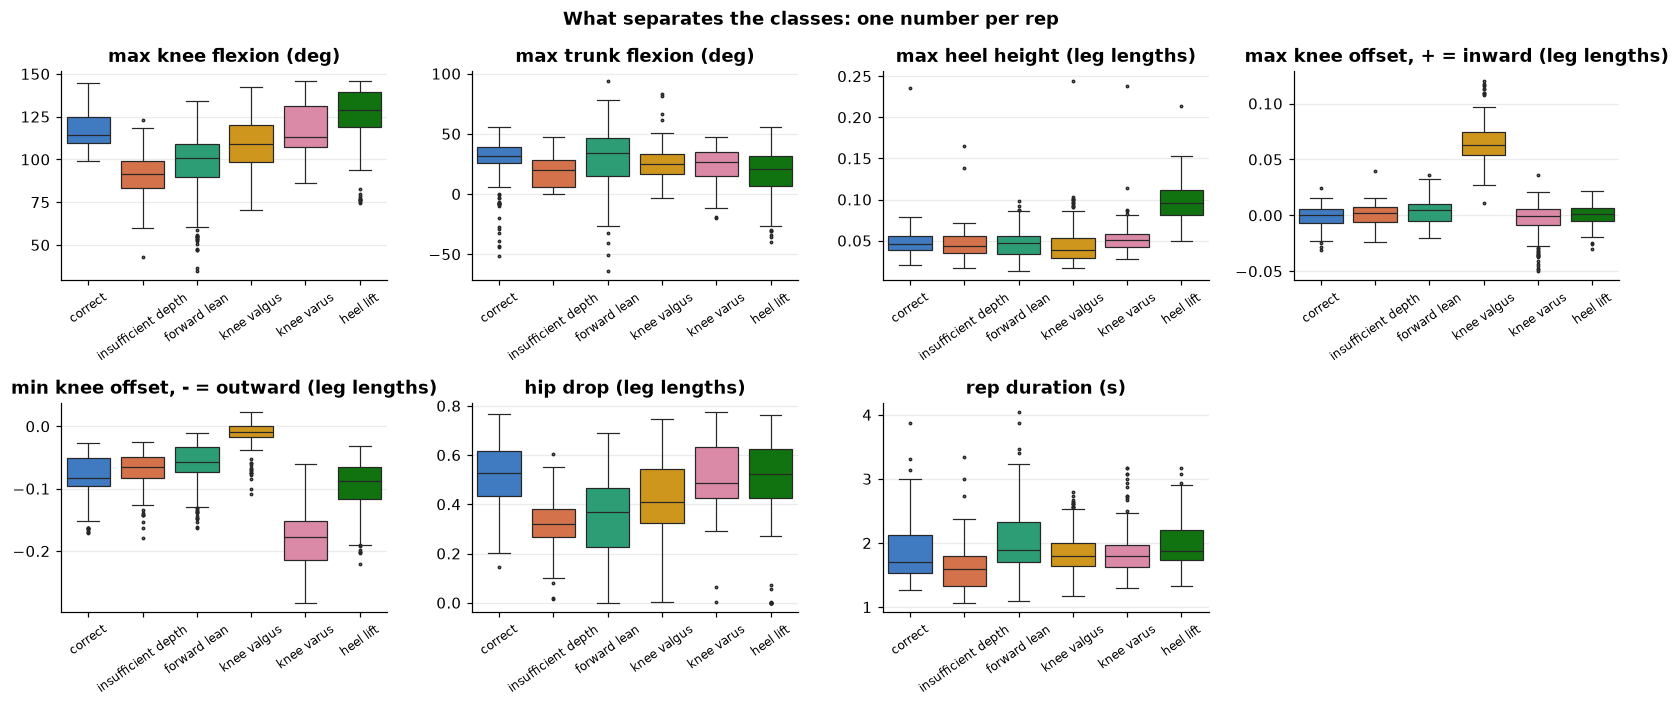

In [9]:
viz.feature_boxplots(ds, OUT); plt.show()
viz.rep_features_table(ds).groupby("class").median().to_csv(OUT / "per_class_feature_medians.csv")

Each error has a visible signature: knee offset inward for valgus and outward for varus, heel height for heel lift,
less knee flexion and hip drop for insufficient depth, more trunk flexion for forward lean. `correct` overlaps with
several classes because each person's normal squat is different, so the person is the main source of variation and
every split keeps all reps of a person on one side.

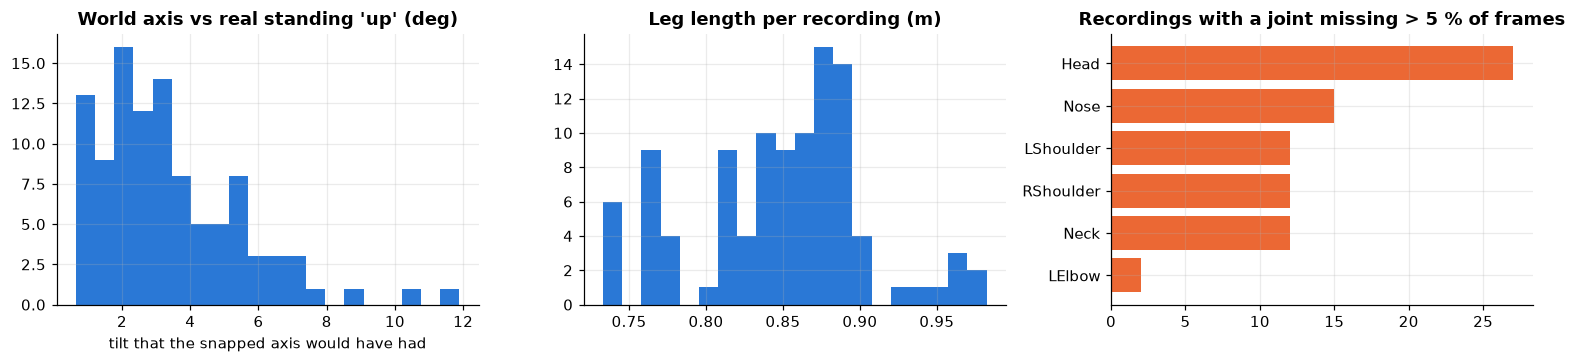

,count,mean,std,min,25%,50%,75%,max
leg_length_m,103.0,0.849,0.055,0.733,0.818,0.855,0.883,0.982
up_tilt_deg,103.0,3.384,2.104,0.648,1.884,2.928,4.542,11.892
n_reps,103.0,10.369,0.990,9.000,10.000,10.000,10.000,14.000


In [10]:
viz.quality(ds, OUT); plt.show()
q = pd.DataFrame(ds["meta"]["recordings"]).T[["leg_length_m", "up_tilt_deg", "n_reps"]].astype(float)
q.to_csv(OUT / "recording_quality.csv"); display(q.describe().T)